# Cardiac CEST apparent pool contrasts
## Problem
Infer six apparent saturation components and a local water-resonance shift from a measured mouse cardiac RF-offset acquisition. Spectral overlap, broad water/MT backgrounds, motion and field variation make the components ambiguous. **No independent ground truth exists.** The original method result is a reproducibility reference, not biological truth. Amplitudes are not molecular concentrations or exchange rates.

## Current benchmark evaluation (v2, 2026-10-29)

The v2 Judge independently evaluates every supported voxel and every53-frequency observation under the six-pool model. Each voxel MSE must be no higher than attained baseline MSE+1e-6; original whole-field RMS boundary and all physical ranges/support constraints remain. No ground truth exists. Independent bounded linear-amplitude fitting produces a different improved solution accepted by the Judge.19 unit tests passed. See cest_pytest.log.

Reference/source-stage and map-similarity comparisons below are retained as historical v1 diagnostics; they do not assert current v2 acceptance boundaries. Current standalone Judge callers retain the same generic report interface.

In [1]:
import os,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'data/raw_data.npz').exists():root=root.parent
os.chdir(root)
from src.preprocessing import load_data,normalize
from src.main import run
from src.solvers import joint_refine_spectrum,LB_BG,UB_BG,LB_POOLS,UB_POOLS
from src.physics_model import predict,POOL_NAMES
from src.visualization import acquisition_figure,amplitude_figure,spectral_parameter_figure,spectrum_figure,reference_figure,residual_figure,bound_activity
from evaluation.judge import evaluate
image,offsets,mask=load_data()
spectra,fit_offsets,normalization=normalize(image,offsets)
print('Complete native acquisition:',image.shape,'supported pixels:',mask.sum(),'fitted offsets:',len(fit_offsets))


Complete native acquisition: (192, 192, 62) supported pixels: 8936 fitted offsets: 53


## Data
The complete192×192×62 measured Bruker7T scan uses a1.1µT pulsed saturation preparation. Four receiver channels and1000 radial projections were reconstructed using the original BART branch before magnitude receiver combination; this benchmark begins with those processed measured images. It does not substitute online ParaVision images for the selected radial branch.

Nine interspersed far-offset reference frames bracket53 saturation samples. Linear interpolation in acquisition index estimates unsaturated signal drift. The public mask depends only on the first reference magnitude, not fitted contrasts, and includes surrounding visible tissue as well as the cardiac region. Every supported pixel remains in the benchmark. There is no fitted-value filtering.

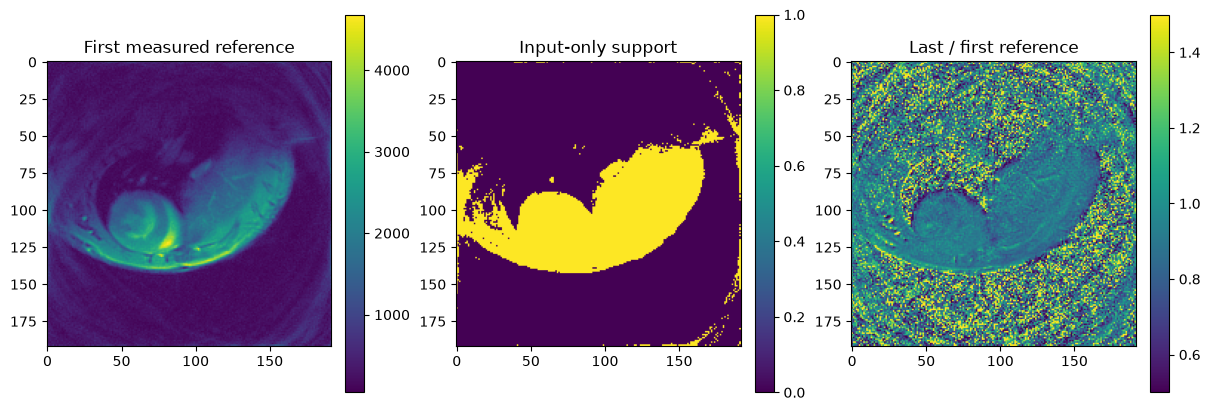

Reference intensity units are arbitrary; normalized spectra are dimensionless.


In [2]:
acquisition_figure(image,mask,normalization)
plt.show()
print('Reference intensity units are arbitrary; normalized spectra are dimensionless.')


## Physics
For normalized signal Z, the apparent model is1 minus a sum of six Lorentzian components. A component of amplitude a, FWHM w and center c contributes a(w²/4)/(w²/4+(omega-b-c)²), where omega is applied offset and b is the local water shift. All frequency quantities are in ppm; a is a fractional attenuation. The model describes water, broad MT, amide, creatine and two NOE bands.

Weak component widths and centers can be unstable. A good reprojection does not identify unique molecular pools. Magnitude noise and partial volumes also limit the model; no independent noise variance is supplied.

## Method
Actively fit every supported spectrum with cleaned local code. First fit water+MT to estimate a frequency origin. After shifting offsets, fit background on the far wings and central water region; finally fit four weak components to the residual attenuation across all53 offsets. The inverse uses explicit local Lorentzians and bounded general least squares, preserving the original model, ordering, signs, crop conditions and numerical conventions. The configured maximum500 evaluations was chosen before the original full run; no original pixel failed.

The two-step method is not a simultaneous optimum of the full six-component objective. The selected-pixel joint refinement below is a separately computed diagnostic, not a substitute for the benchmark reconstruction.

In [3]:
start=time.perf_counter()
parameters,field=run()
runtime=time.perf_counter()-start
report,exit_code=evaluate('output/reconstruction.npz')
assert exit_code==0,report
with np.load('notebooks/reference_outputs/upstream_fit.npz',allow_pickle=False) as z:
    upstream=z['parameters'][0]
    upstream_field=z['field_shift'][0]
np.testing.assert_allclose(parameters,upstream,rtol=1e-7,atol=1e-8)
np.testing.assert_allclose(field,upstream_field,rtol=1e-7,atol=1e-8)
np.savez_compressed('notebooks/reference_outputs/fresh_fit.npz',parameters=parameters[None],field_shift=field[None])
print('Fresh full reconstruction seconds:',runtime)
print(json.dumps(report,indent=2))


Fresh full reconstruction seconds: 169.90996909991372
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "amplitude_water_rmse": 0.0,
    "amplitude_mt_rmse": 0.0,
    "amplitude_amide_rmse": 0.0,
    "amplitude_creatine_rmse": 0.0,
    "amplitude_noe35_rmse": 0.0,
    "amplitude_noe16_rmse": 0.0,
    "width_water_rmse": 0.0,
    "width_mt_rmse": 0.0,
    "width_amide_rmse": 0.0,
    "width_creatine_rmse": 0.0,
    "width_noe35_rmse": 0.0,
    "width_noe16_rmse": 0.0,
    "center_water_rmse": 0.0,
    "center_mt_rmse": 0.0,
    "center_amide_rmse": 0.0,
    "center_creatine_rmse": 0.0,
    "center_noe35_rmse": 0.0,
    "center_noe16_rmse": 0.0,
    "field_shift_rmse": 1.218512846681098e-16,
    "observation_rmse": 0.07805802475666919
  },
  "thresholds": {
    "amplitude_water_rmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "amplitude_mt_rmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "amplitude_amide_rmse": {
      "comparison": "<="

## Results
The six maps below show freshly inferred **apparent peak attenuation**, with different physically declared amplitude ranges indicated by the color bars. Blank pixels are outside the fixed observation support; they are not failed or removed fits.

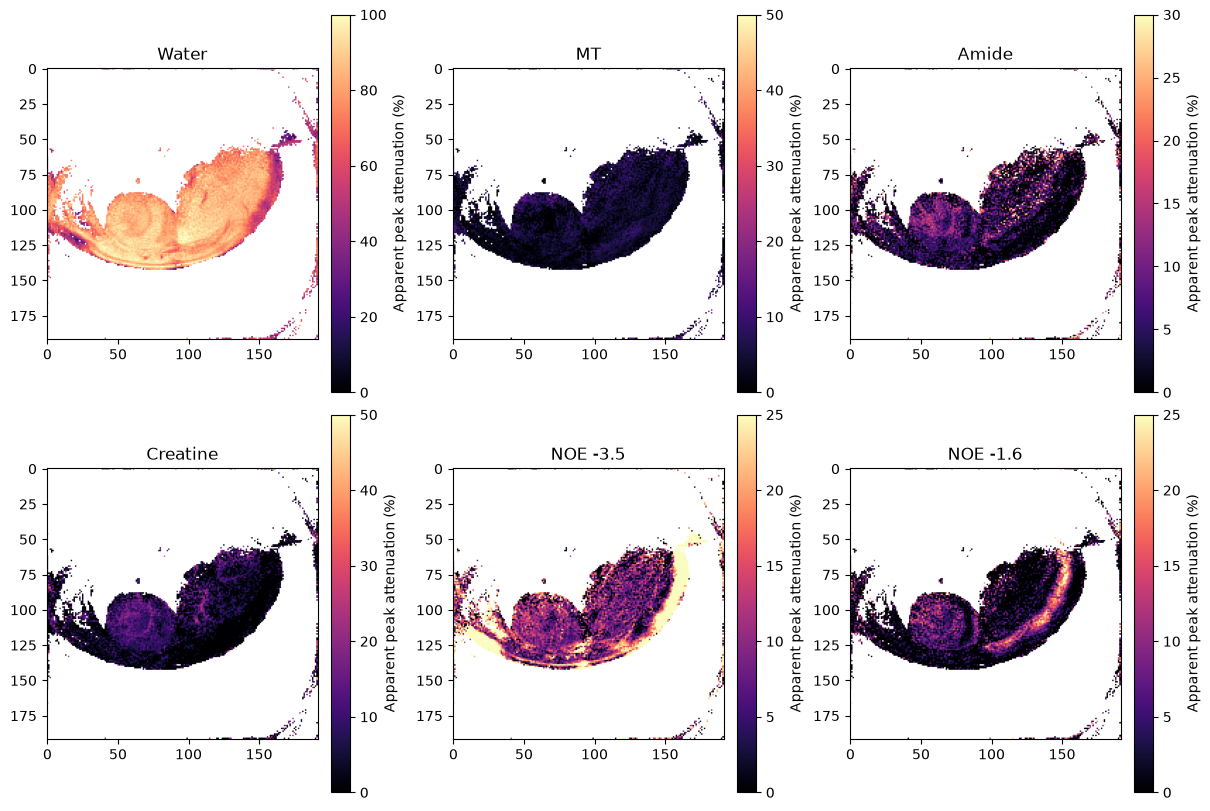

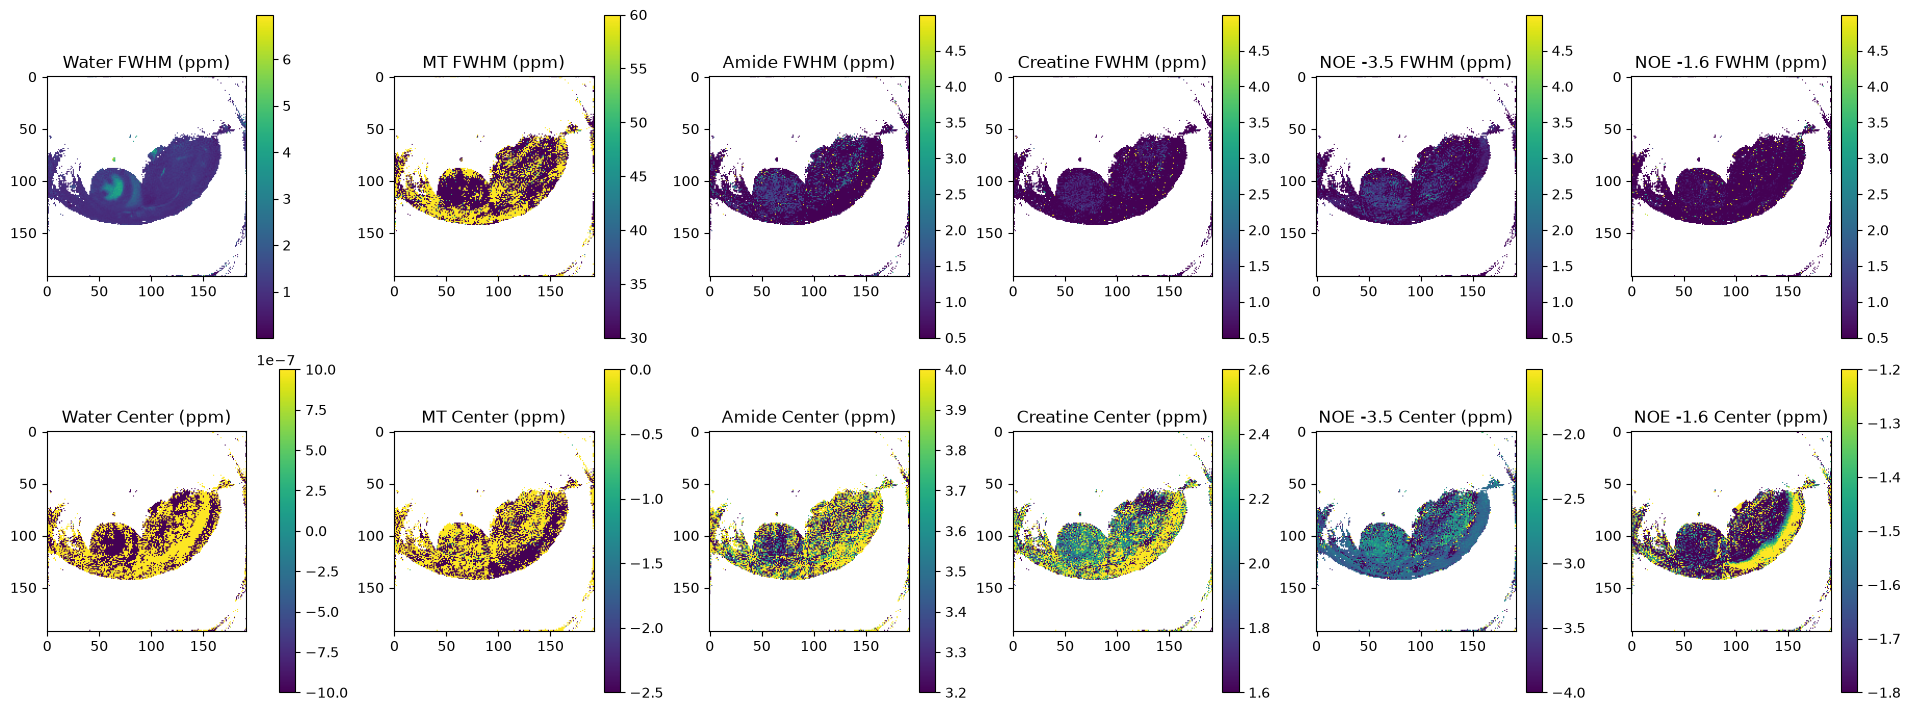

In [4]:
amplitude_figure(parameters,mask)
plt.show()
spectral_parameter_figure(parameters,field,mask)
plt.show()


### Measured spectra and a computed joint-fit comparison
Choose three supported locations by fixed quartiles of the native support ordering. All observed frequencies remain in each plot. Refit all six components jointly for these same three measured spectra while holding the independently computed field shift fixed. The refinement can reduce residual but does not establish more accurate chemistry. A2000-evaluation cap is retained; the actual final iterate is plotted even when convergence is not achieved, with status reported explicitly. No cached or zero replacement is supplied. Lower panels display the actual fresh two-step component contributions.

[
  {
    "pixel": [
      86,
      14
    ],
    "two_step_rmse": 0.14720656381086777,
    "joint_rmse": 0.14289306958412418,
    "converged": true,
    "evaluations": 29,
    "message": "`ftol` termination condition is satisfied."
  },
  {
    "pixel": [
      104,
      137
    ],
    "two_step_rmse": 0.04322837430920981,
    "joint_rmse": 0.03590929230534584,
    "converged": false,
    "evaluations": 2000,
    "message": "The maximum number of function evaluations is exceeded."
  },
  {
    "pixel": [
      120,
      88
    ],
    "two_step_rmse": 0.03457595421615451,
    "joint_rmse": 0.0329888305285103,
    "converged": true,
    "evaluations": 16,
    "message": "`ftol` termination condition is satisfied."
  }
]


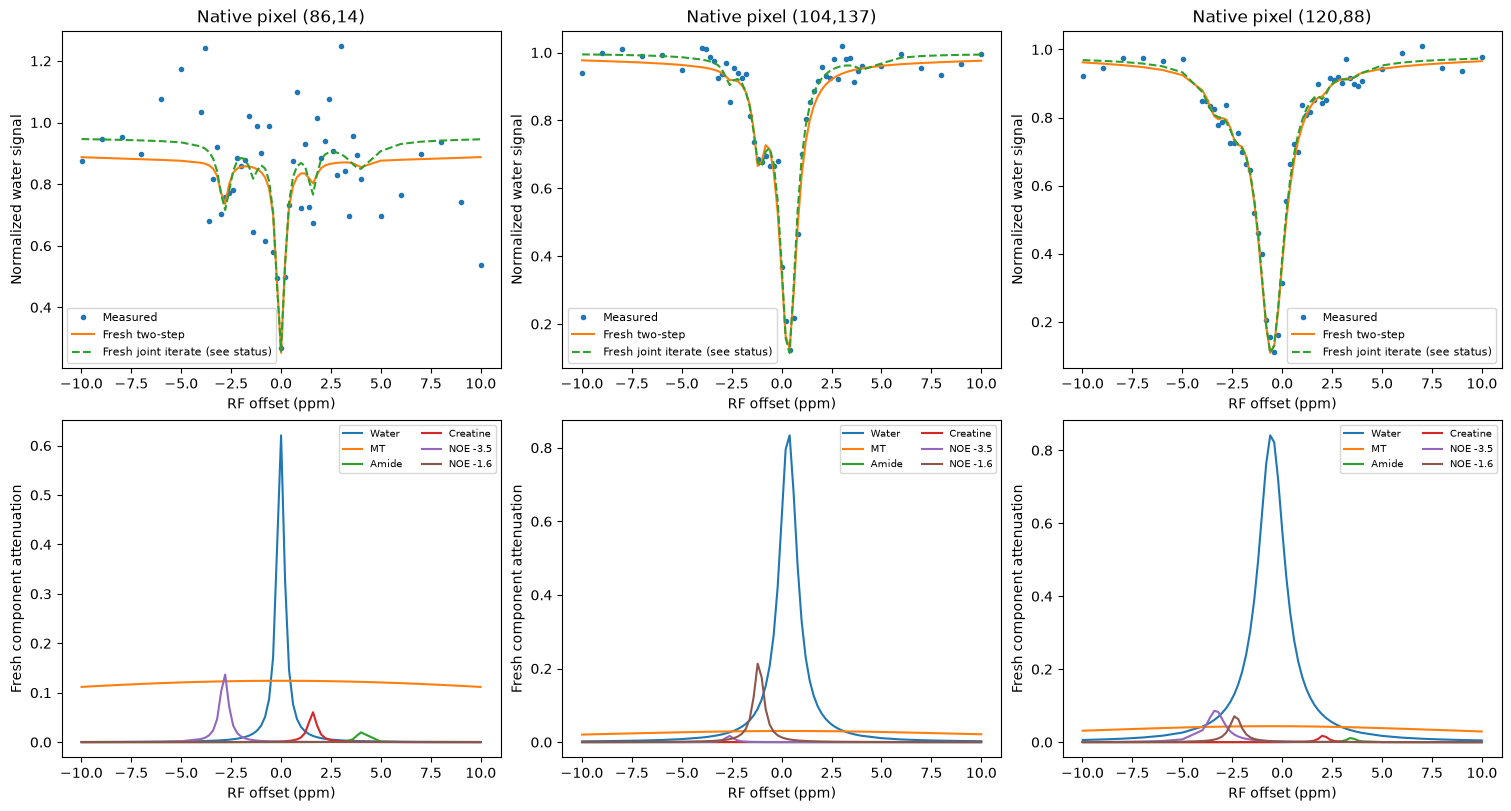

In [5]:
coords=np.argwhere(mask)
positions=coords[[len(coords)//4,len(coords)//2,3*len(coords)//4]]
joint=[];joint_metrics=[]
for y,x in positions:
    q,status=joint_refine_spectrum(spectra[y,x],fit_offsets,parameters[y,x],field[y,x])
    joint.append(q)
    before=float(np.sqrt(np.mean((predict(fit_offsets,parameters[y,x],field[y,x])-spectra[y,x])**2)))
    after=float(np.sqrt(np.mean((predict(fit_offsets,q,field[y,x])-spectra[y,x])**2)))
    assert after<=before+1e-10
    joint_metrics.append({'pixel':[int(y),int(x)],'two_step_rmse':before,'joint_rmse':after,**status})
print(json.dumps(joint_metrics,indent=2))
spectrum_figure(spectra,fit_offsets,parameters,field,positions,joint)
plt.show()


### Independent original agreement and field-shift ablation
Original and fresh amplitudes are compared for every supported pixel. The next ablation holds the freshly inferred six parameter triples fixed and sets only the field shift to zero during reprojection. It is a **forward-model ablation**, not an uncomputed alternative reconstruction. Both residual distributions use all8936 supported pixels and all53 saturation offsets.

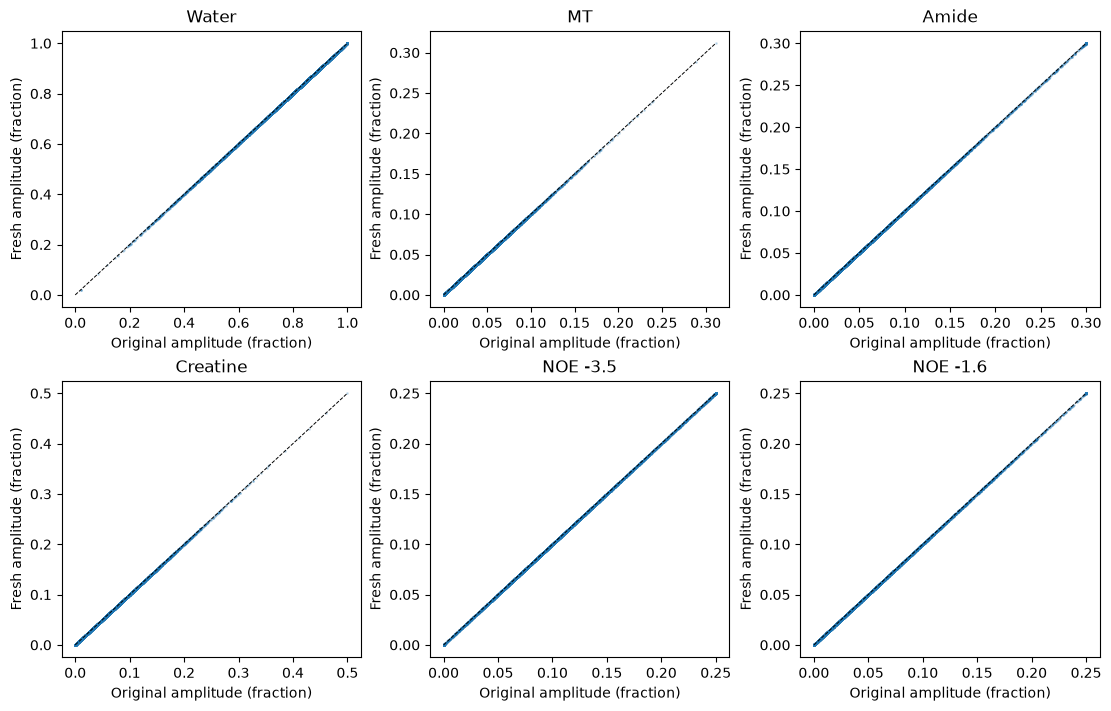

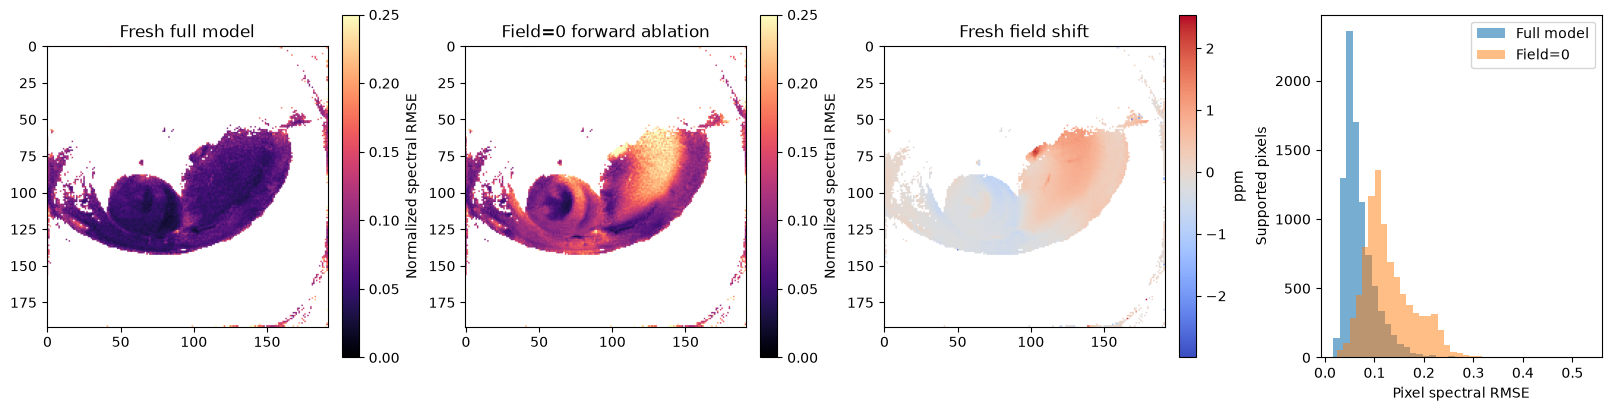

Near-bound tolerance: one-millionth of the individual parameter-box range, including the narrow water-center gauge.
Component | amplitude / width / center bound fractions
Water [2.12623098e-03 2.23813787e-04 7.96665175e-01]
MT [0.13104297 0.4707923  0.80494628]
Amide [0.26980752 0.37746195 0.30875112]
Creatine [0.35049239 0.62891674 0.16528648]
NOE -3.5 [0.17423903 0.24485228 0.064906  ]
NOE -1.6 [0.36235452 0.51969561 0.38943599]
All-offset RMS full / fixed-parameter field=0: 0.07805802475666919 0.138800399463304


4188

In [6]:
reference_figure(parameters,upstream,mask)
plt.show()
fig,errors,ablated=residual_figure(spectra,fit_offsets,parameters,field,mask)
plt.show()
lower=np.array(LB_BG+LB_POOLS).reshape(6,3)
upper=np.array(UB_BG+UB_POOLS).reshape(6,3)
bound_fraction=bound_activity(parameters,mask,lower,upper)
print('Near-bound tolerance: one-millionth of the individual parameter-box range, including the narrow water-center gauge.')
print('Component | amplitude / width / center bound fractions')
for name,row in zip(POOL_NAMES,bound_fraction):print(name,row)
print('All-offset RMS full / fixed-parameter field=0:',np.sqrt(np.mean(errors**2)),np.sqrt(np.mean(ablated**2)))
measurements={'runtime_seconds':runtime,'judge':report,'selected_pixel_joint_comparison':joint_metrics,'bound_fraction':bound_fraction.tolist(),'forward_ablation_rmse':float(np.sqrt(np.mean(ablated**2)))}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf-8')


## Conclusion
The complete fresh reconstruction reproduces the independently executed original pipeline. The maps, observed spectra, explicit component curves, bound activity and all-pixel forward ablation show what the decomposition explains and where ambiguity remains. A lower selected-pixel joint-fit residual does not validate a biochemical interpretation.

These are apparent saturation components in a processed measured cardiac acquisition. Motion correction and PCA were not applied; the mask is signal support rather than myocardium segmentation. Numerical reference agreement, spectral residual and biochemical accuracy remain distinct claims. No exchange rate, molecular concentration, true component map or calibrated uncertainty interval has been invented.